# Solution: Mission 02 — Tipping Geography Story

This notebook is one possible solution. Try the mission yourself before you read it.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent.parent / "tools"))
import datasets

COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "trip_distance",
        "fare_amount", "tip_amount", "total_amount", "payment_type"]

def load_month(month: str) -> pd.DataFrame:
    df = pd.read_parquet(datasets.taxi(month), columns=COLS)
    start = pd.Timestamp(month + "-01")
    dur = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    ok = (df["tpep_pickup_datetime"].between(start, start + pd.offsets.MonthBegin(1), inclusive="left")
          & dur.between(1, 180) & df["trip_distance"].between(0.1, 100) & df["fare_amount"].between(3, 500))
    return df[ok].assign(duration_min=dur[ok])

zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))
trips = load_month("2024-02")
trips["borough"] = trips["PULocationID"].map(zones.set_index("LocationID")["Borough"])

import geopandas as gpd

gdf = gpd.read_file(f"zip://{datasets.fetch('taxi_zones.zip')}!taxi_zones/taxi_zones.shp")
gdf["area_km2"] = gdf.geometry.area * 0.3048 ** 2 / 1e6
card = trips[trips["payment_type"] == 1]
print(f"{len(trips):,} trips, {len(card):,} card trips, {len(gdf)} zones")

2,885,850 trips, 2,316,843 card trips, 263 zones


## Task 1: Metric

**Tip rate of a zone** = sum of tips / sum of fares, over **card** trips that start in the zone. A ratio of sums weights every dollar equally (M09 L10). Zones need at least **200 card trips** in February; smaller zones are not shown (noise and privacy).

In [2]:
MIN_TRIPS = 200
zone = card.groupby("PULocationID").agg(card_trips=("fare_amount", "size"), fares=("fare_amount", "sum"), tips=("tip_amount", "sum"),
                                        median_distance=("trip_distance", "median"))
zone["tip_rate"] = 100 * zone["tips"] / zone["fares"]
shown = zone[zone["card_trips"] >= MIN_TRIPS]
print(f"zones with card trips: {len(zone)}, shown (>= {MIN_TRIPS} trips): {len(shown)}")
print(f"tip rate across shown zones: {shown['tip_rate'].min():.1f}% to {shown['tip_rate'].max():.1f}%")

zones with card trips: 244, shown (>= 200 trips): 118
tip rate across shown zones: 0.0% to 25.0%


## Task 4 (first): Privacy and Suppression

In [3]:
suppressed = zone[zone["card_trips"] < MIN_TRIPS]
print(f"suppressed zones: {len(suppressed)} ({suppressed['card_trips'].sum():,} card trips, "
      f"{suppressed['card_trips'].sum() / zone['card_trips'].sum():.2%} of all card trips)")

suppressed zones: 126 (10,273 card trips, 0.44% of all card trips)


## Task 2: The Map

A **sequential** palette (`cividis`, colour-blind safe and readable in greyscale) suits an ordered rate. The rates of the shown zones are not extremely skewed, so **quantile classes** (5 groups with equal numbers of zones) make the ranking easy to read; the legend states the class limits.

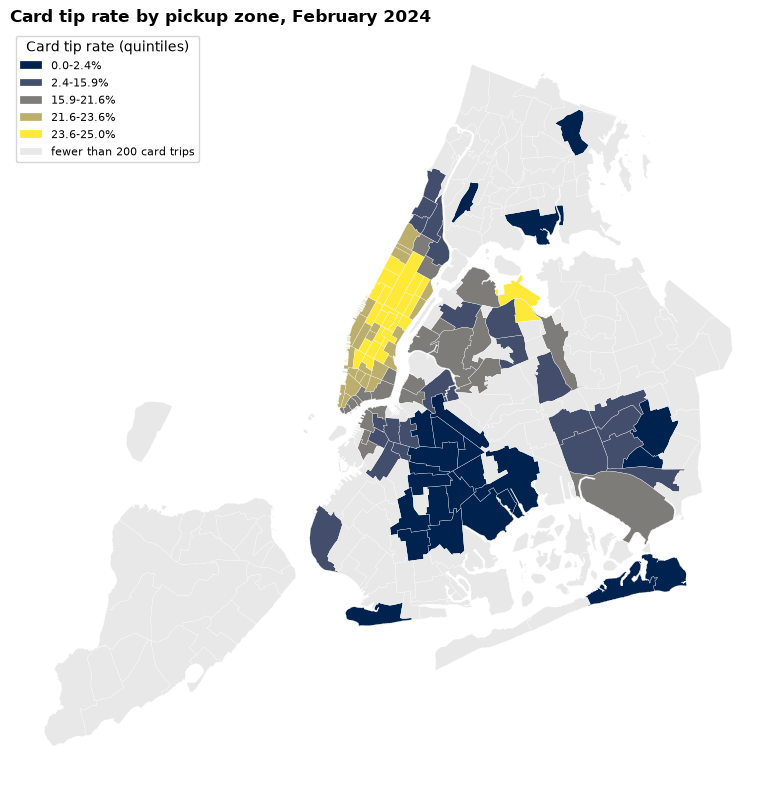

In [4]:
m = gdf.merge(shown[["tip_rate", "card_trips"]], left_on="LocationID", right_index=True, how="left")
classes, edges = pd.qcut(m["tip_rate"], 5, retbins=True)
labels = [f"{edges[i]:.1f}-{edges[i + 1]:.1f}%" for i in range(5)]
m["class"] = pd.qcut(m["tip_rate"], 5, labels=labels)

fig, ax = plt.subplots(figsize=(8, 8))
m.plot(column="class", categorical=True, cmap="cividis", legend=True, ax=ax, edgecolor="white", linewidth=0.2,
       missing_kwds={"color": "#E8E8E8", "label": f"fewer than {MIN_TRIPS} card trips"},
       legend_kwds={"title": "Card tip rate (quintiles)", "loc": "upper left", "fontsize": 8})
top = shown["tip_rate"].idxmax()
ax.set_title("Card tip rate by pickup zone, February 2024", loc="left", fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
map_fig = fig
plt.show()

## Task 3: The Storyboard

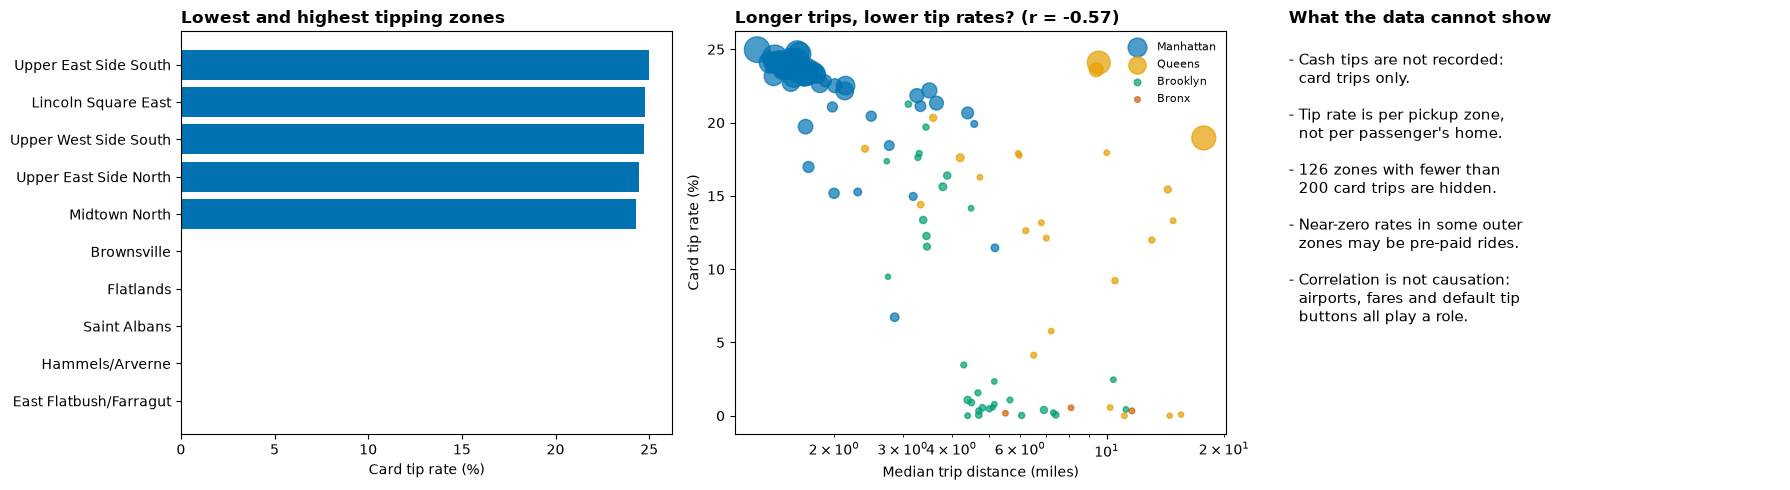

                 zone   borough  card_trips  tip_rate
Upper West Side South Manhattan       71977      24.7
  Lincoln Square East Manhattan       77733      24.8
Upper East Side South Manhattan      114069      25.0


In [5]:
names = zones.set_index("LocationID")["Zone"]
boroughs = zones.set_index("LocationID")["Borough"]
ranked = shown.assign(zone=lambda d: d.index.map(names), borough=lambda d: d.index.map(boroughs)).sort_values("tip_rate")
corr = np.corrcoef(shown["median_distance"], shown["tip_rate"])[0, 1]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ext = pd.concat([ranked.head(5), ranked.tail(5)])
axes[0].barh(ext["zone"], ext["tip_rate"], color=["#767676"] * 5 + ["#0072B2"] * 5)
axes[0].set(xlabel="Card tip rate (%)", xlim=(0, None))
axes[0].set_title("Lowest and highest tipping zones", loc="left", fontweight="bold")
for b, c in zip(["Manhattan", "Queens", "Brooklyn", "Bronx"], ["#0072B2", "#E69F00", "#009E73", "#D55E00"]):
    part = ranked[ranked["borough"] == b]
    axes[1].scatter(part["median_distance"], part["tip_rate"], s=np.sqrt(part["card_trips"]), color=c, alpha=0.7, label=b)
axes[1].set(xlabel="Median trip distance (miles)", ylabel="Card tip rate (%)", xscale="log")
axes[1].set_title(f"Longer trips, lower tip rates? (r = {corr:.2f})", loc="left", fontweight="bold")
axes[1].legend(frameon=False, fontsize=8)
axes[2].axis("off")
axes[2].set_title("What the data cannot show", loc="left", fontweight="bold")
axes[2].text(0, 0.95, "- Cash tips are not recorded:\n  card trips only.\n\n- Tip rate is per pickup zone,\n  not per passenger's home.\n\n"
             f"- {len(suppressed)} zones with fewer than\n  {MIN_TRIPS} card trips are hidden.\n\n- Near-zero rates in some outer\n  zones may be pre-paid rides.\n\n- Correlation is not causation:\n"
             "  airports, fares and default tip\n  buttons all play a role.", va="top", fontsize=11)
plt.tight_layout()
plt.show()
print(ranked[["zone", "borough", "card_trips", "tip_rate"]].tail(3).round(1).to_string(index=False))

Several outer-borough zones show almost no card tips (for example Hammels/Arverne and Saint Albans in Queens). A rate near zero probably describes **how** these trips were paid (pre-arranged or agency-paid rides), not how generous passengers are. A story must say this, or readers will draw the wrong conclusion.

## Task 5: Publish

In [6]:
import tempfile

import folium

out = Path(tempfile.mkdtemp())
map_fig.savefig(out / "tip_rate_map.png", dpi=200, facecolor="white", bbox_inches="tight")
alt_text = (f"Map of New York City taxi zones coloured by the card tip rate of trips starting there in February 2024. "
            f"Rates range from {shown['tip_rate'].min():.0f}% to {shown['tip_rate'].max():.0f}%; "
            f"the highest rate is in {names[top]} ({shown.loc[top, 'tip_rate']:.1f}%). Grey zones have too few trips to show.")

web = m.dropna(subset=["tip_rate"])[["LocationID", "zone", "borough", "tip_rate", "card_trips", "geometry"]].copy()
web["geometry"] = web.geometry.simplify(100)
web = web.to_crs(4326)
fmap = folium.Map(location=[40.73, -73.93], zoom_start=10, tiles="OpenStreetMap")
folium.Choropleth(geo_data=web.to_json(), data=web, columns=["LocationID", "tip_rate"], key_on="feature.properties.LocationID",
                  fill_color="YlGnBu", bins=list(edges), fill_opacity=0.75, line_weight=0.3, legend_name="Card tip rate (%)").add_to(fmap)
folium.GeoJson(web.to_json(), style_function=lambda f: {"fillOpacity": 0, "weight": 0},
               tooltip=folium.GeoJsonTooltip(fields=["zone", "borough", "tip_rate", "card_trips"],
                                             aliases=["Zone", "Borough", "Tip rate %", "Card trips"], localize=True)).add_to(fmap)
fmap.save(out / "tip_rate_map.html")
for p in sorted(out.iterdir()):
    print(f"{p.name}: {p.stat().st_size / 1024:.0f} KiB")
print("\nalt text:", alt_text)
assert not set(web["LocationID"]) & set(suppressed.index), "a suppressed zone was published"
print("check passed: no suppressed zone in the published map")

tip_rate_map.html: 296 KiB
tip_rate_map.png: 331 KiB

alt text: Map of New York City taxi zones coloured by the card tip rate of trips starting there in February 2024. Rates range from 0% to 25%; the highest rate is in Upper East Side South (25.0%). Grey zones have too few trips to show.
check passed: no suppressed zone in the published map
